# Explore an ICF with Pandas and Matplotlib

Two small examples: explore memory channels as a table, then plot stored repeater coordinates.
The default input is fictional and built through the installed Rust binding; no radio, original assets, or external map service is used.
Nothing is written back to the ICF.
The synthetic ICF builder is included in the folded setup cell below.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from cs705 import Icf
from cs705.icf import MemorySide, RepeaterCoordinate, RepeaterPosition
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

ICF_PATH: Path | None = None  # Set to Path("backup.icf") to use a real file.

In [2]:
# Synthetic setup only: never write this image to a radio.
from cs705.icf import (
    MemoryMode,
    RepeaterDuplex,
    RepeaterMode,
    RepeaterRecord,
    RepeaterTone,
)
from cs705.icf.record import ChannelField, decode_mode, reset_holder
from cs705.icf.rows import NormalMemory


def demo_icf() -> Icf:
    """Return a parsed, fictional backup, not a factory or radio-compatible image."""
    working = bytearray(0x4997A)
    working[0x355A1] = 6
    working[0x3C9B0:0x3C9C0] = b"IcomCloneFormat3"
    # Empty normal-memory flags and DWORD map cells (NOTES.md 2.1).
    working[0x3662D : 0x3662D + 500] = b"\x01" * 500
    working[0x3FCD4 : 0x3FCD4 + 40_000] = (0xFFFF).to_bytes(4, "little") * 10_000
    model = NormalMemory.from_working(bytes(working))
    groups = (
        ("Local", MemoryMode.Fm, (145_500_000, 145_525_000, 430_100_000, 430_125_000)),
        ("Travel", MemoryMode.Fm, (145_500_000, 145_550_000, 430_100_000, 433_000_000)),
        ("HF", MemoryMode.Usb, (7_100_000, 14_074_000, 28_400_000, 50_100_000)),
    )
    for group, (name, mode, frequencies) in enumerate(groups):
        if not model.add_group():
            raise RuntimeError("cannot create synthetic memory group")
        model.rename_group(group, name.encode("ascii"))
        if model.allocate(group, range(len(frequencies))).allocated != len(frequencies):
            raise RuntimeError("cannot allocate synthetic memory rows")
        for row, frequency in enumerate(frequencies):
            index = group * 200 + row * 2
            holder = reset_holder(2, index, 0)
            holder.set_valid(True)
            holder.set_mode(decode_mode(mode.value))
            holder.set_name(f"DEMO {group}/{row}".encode("ascii").ljust(16))
            holder.set_channel_field(ChannelField.FrequencyHz, frequency)
            model.store_channel(index, holder)

    # Seed only repeater occupancy/group links; native setters write every row.
    # These are the storage windows documented in src/icf/repeaters.rs.
    memory = bytearray(model.to_icf().memory())
    memory[0x3AB82:0x3BF0A] = b"\xff" * 5000
    memory[0x3BF0A:0x3BF6E] = b"\xff" * 100
    coordinates = (
        (35, 42_000, 139, 30_000),
        (35, 48_000, 139, 36_000),
        (35, 45_000, 139, 48_000),
        (35, 33_000, 139, 42_000),
        (35, 36_000, 139, 54_000),
        (35, 28_000, 139, 35_000),
        (35, 24_000, 139, 51_000),
        (35, 18_000, 139, 30_000),
        (0, 0, 0, 0),
    )
    for slot in range(len(coordinates)):
        at = 0x3AB82 + slot * 2
        memory[at : at + 2] = slot.to_bytes(2, "little")
        at = 0xAA0F + slot * 52 + 8
        memory[at : at + 2] = b"\xff\xff"  # No gateway reference.
    for group in range(3):
        at = 0x3BF0A + group * 2
        memory[at : at + 2] = (group * 3).to_bytes(2, "little")
    image = Icf.from_memory(bytes(memory))
    for group, name in enumerate(("Demo North", "Demo Central", "Demo South")):
        image.set_repeater_group_name_ascii(group, name)
    for slot, (lat, lat_minutes, lon, lon_minutes) in enumerate(coordinates):
        mode = RepeaterMode.Dv if slot % 2 == 0 else RepeaterMode.Fm
        position = RepeaterPosition.Exact
        if slot >= 6:
            position = RepeaterPosition.Approximate
        if slot == 8:
            position = getattr(RepeaterPosition, "None")
        image.set_physical_repeater(
            slot,
            RepeaterRecord(
                name=f"DEMO {slot:02}".encode("ascii").ljust(16),
                sub_name=b"FICTION ",
                repeater_call=f"DEMO{slot:03} ".encode("ascii"),
                gateway_call=b" " * 8,
                frequency_hz=145_100_000 + slot * 25_000
                if slot < 4
                else 430_100_000 + slot * 12_500,
                offset_hz=600_000,
                mode=mode,
                duplex=RepeaterDuplex.Minus,
                tone=RepeaterTone.Off,
                tone_index=0 if mode == RepeaterMode.Fm else None,
                use_repeater=True,
                position=position,
                utc_offset_minutes=0,
                latitude=RepeaterCoordinate(lat, lat_minutes, False),
                longitude=RepeaterCoordinate(lon, lon_minutes, False),
            ),
        )
    image = Icf.parse(image.to_bytes())
    assert (
        sum(slot is not None for g in image.memory_groups() for slot in g.slots()) == 12
    )
    assert sum(len(g.physical_slots()) for g in image.repeater_groups()) == 9
    last = image.physical_repeater(8)
    assert last is not None and last.position == getattr(RepeaterPosition, "None")
    return image

In [3]:
image = demo_icf() if ICF_PATH is None else Icf.parse(ICF_PATH.read_bytes())
print("SYNTHETIC DEMO" if ICF_PATH is None else f"Input: {ICF_PATH}")

SYNTHETIC DEMO


## 1. Explore the memory table

Resolve saved group/row positions to physical slots before reading fields.
Only Main/RX fields are listed; names stay bytes, so no text encoding is guessed.

In [4]:
memory_rows = []
for group, bank in enumerate(image.memory_groups()):
    for row, slot in enumerate(bank.slots()):
        if slot is not None:
            memory_rows.append(
                {
                    "group": group,
                    "row": row,
                    "name": image.physical_memory_name_raw(slot),
                    "frequency_hz": image.physical_memory_frequency_hz(
                        slot, MemorySide.Main
                    ),
                    "mode": image.physical_memory_mode(slot, MemorySide.Main).name,
                }
            )
channels = pd.DataFrame(
    memory_rows, columns=["group", "row", "name", "frequency_hz", "mode"]
)
channels

,group,row,name,frequency_hz,mode
0,0,0,b'DEMO 0/0 ',145500000,Fm
1,0,1,b'DEMO 0/1 ',145525000,Fm
2,0,2,b'DEMO 0/2 ',430100000,Fm
3,0,3,b'DEMO 0/3 ',430125000,Fm
4,1,0,b'DEMO 1/0 ',145500000,Fm
5,1,1,b'DEMO 1/1 ',145550000,Fm
6,1,2,b'DEMO 1/2 ',430100000,Fm
7,1,3,b'DEMO 1/3 ',433000000,Fm
8,2,0,b'DEMO 2/0 ',7100000,Usb
9,2,1,b'DEMO 2/1 ',14074000,Usb


Filter the table and find repeated receive-frequency/mode pairs.
Matching pairs are candidates for review, not proof of duplicate settings: tones, split/TX fields and digital callsigns are not compared.

In [5]:
display(channels.query("144_000_000 <= frequency_hz <= 146_000_000 and mode == 'Fm'"))
display(
    channels[channels.duplicated(["frequency_hz", "mode"], keep=False)].sort_values(
        ["frequency_hz", "group", "row"]
    )
)
channels.groupby(["group", "mode"]).size().rename("channels")

,group,row,name,frequency_hz,mode
0,0,0,b'DEMO 0/0 ',145500000,Fm
1,0,1,b'DEMO 0/1 ',145525000,Fm
4,1,0,b'DEMO 1/0 ',145500000,Fm
5,1,1,b'DEMO 1/1 ',145550000,Fm


,group,row,name,frequency_hz,mode
0,0,0,b'DEMO 0/0 ',145500000,Fm
4,1,0,b'DEMO 1/0 ',145500000,Fm
2,0,2,b'DEMO 0/2 ',430100000,Fm
6,1,2,b'DEMO 1/2 ',430100000,Fm


group  mode
0      Fm      4
1      Fm      4
2      Usb     4
Name: channels, dtype: int64

## 2. Plot repeater coordinates

Convert whole degrees plus thousandths of a minute, preserving south/west signs.
Records explicitly marked as having no position are counted and excluded; invalid coordinates raise an error rather than being repaired.
Zero degrees is a valid coordinate, not a missing-position marker.

In [6]:
def decimal_degrees(value: RepeaterCoordinate, limit: int) -> float:
    """Validate a stored coordinate and convert it without geographic inference."""
    degrees, minutes = value.degrees, value.thousandths_of_minute
    if degrees > limit or minutes >= 60_000 or (degrees == limit and minutes != 0):
        raise ValueError("Coordinate outside geographic range")
    return (-1 if value.negative else 1) * (degrees + minutes / 60_000)


repeater_rows = []
missing_positions = 0
for group, bank in enumerate(image.repeater_groups()):
    for slot in bank.physical_slots():
        record = image.physical_repeater(slot)
        if record is None:
            raise ValueError("Repeater group refers to an unused slot")
        if record.position == getattr(RepeaterPosition, "None"):
            missing_positions += 1
            continue
        repeater_rows.append(
            {
                "group": group,
                "call": record.repeater_call.rstrip(b" "),
                "mode": record.mode.name,
                "frequency_mhz": record.frequency_hz / 1_000_000,
                "latitude": decimal_degrees(record.latitude, 90),
                "longitude": decimal_degrees(record.longitude, 180),
                "position": record.position.name,
            }
        )
repeaters = pd.DataFrame(
    repeater_rows,
    columns=[
        "group",
        "call",
        "mode",
        "frequency_mhz",
        "latitude",
        "longitude",
        "position",
    ],
)
print(f"Excluded {missing_positions} record(s) with no stored position")
repeaters

Excluded 1 record(s) with no stored position


,group,call,mode,frequency_mhz,latitude,longitude,position
0,0,b'DEMO000',Dv,145.1000,35.700000,139.500000,Exact
1,0,b'DEMO001',Fm,145.1250,35.800000,139.600000,Exact
2,0,b'DEMO002',Dv,145.1500,35.750000,139.800000,Exact
3,1,b'DEMO003',Fm,145.1750,35.550000,139.700000,Exact
4,1,b'DEMO004',Dv,430.1500,35.600000,139.900000,Exact
5,1,b'DEMO005',Fm,430.1625,35.466667,139.583333,Exact
6,2,b'DEMO006',Dv,430.1750,35.400000,139.850000,Approximate
7,2,b'DEMO007',Fm,430.1875,35.300000,139.500000,Approximate


Choose a group or mode below, or leave either filter as `None`.
Color represents stored frequency, circles indicate exact positions, and triangles indicate approximate positions.
This is a longitude/latitude scatter plot, not a coverage prediction or a distance-preserving map.
At most 20 points are labelled to keep dense plots readable.

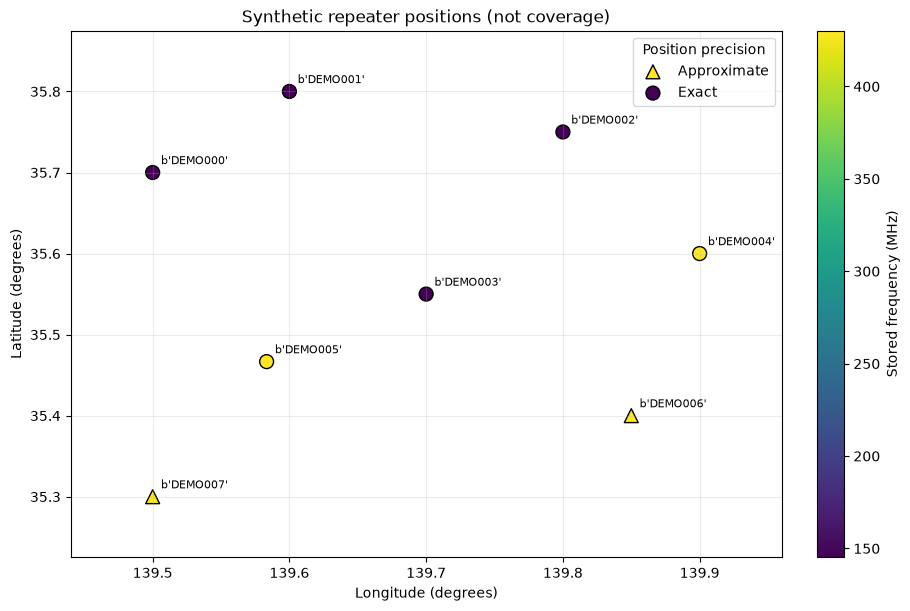

In [7]:
GROUP: int | None = None
MODE: str | None = None  # For example, "Fm" or "Dv".
selected = repeaters
if GROUP is not None:
    selected = selected[selected["group"] == GROUP]
if MODE is not None:
    selected = selected[selected["mode"] == MODE]

if selected.empty:
    print("No repeaters with coordinates match the selected filters")
else:
    norm = Normalize(selected["frequency_mhz"].min(), selected["frequency_mhz"].max())
    fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
    for precision, points in selected.groupby("position"):
        ax.scatter(
            points["longitude"],
            points["latitude"],
            c=points["frequency_mhz"],
            marker="^" if precision == "Approximate" else "o",
            cmap="viridis",
            norm=norm,
            s=100,
            edgecolors="black",
            label=precision,
        )
    for point in selected.head(20).itertuples():
        ax.annotate(
            repr(point.call),
            (point.longitude, point.latitude),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=8,
            parse_math=False,
        )
    fig.colorbar(
        ScalarMappable(norm=norm, cmap="viridis"), ax=ax, label="Stored frequency (MHz)"
    )
    ax.set(
        xlabel="Longitude (degrees)",
        ylabel="Latitude (degrees)",
        title=("Synthetic" if ICF_PATH is None else "Stored")
        + " repeater positions (not coverage)",
    )
    ax.ticklabel_format(useOffset=False)
    ax.margins(0.15)
    ax.grid(alpha=0.25)
    ax.legend(title="Position precision")
    plt.show()